# NBA Player Scoring — Complete Final Capstone
Exploratory analysis, baseline, model selection, tuning, and findings for 2024–25 NBA season.

**Research question:** Which same-season player statistics best explain points per game, and how accurately can different regression models estimate scoring?

These are same-season estimates, not predictions of future performance. Shooting attempts and percentages are mathematically connected to points, so high accuracy is expected and does not establish causality.

The dataset is located at 'data/nba_player_stats.csv'.

---
# Part I — Business Understanding, Data Preparation, and Exploratory Analysis

Examine distributions, missingness, scoring relationships, and a transparent linear baseline.

## 1. Imports and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
SEASON = '2024-25'
DATA_PATH = Path('./data/nba_player_stats.csv')
plt.style.use('ggplot')

## 2. Data source and loading
The 2024–25 NBA per-game player-statistics CSV is at `data/nba_player_stats.csv`.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Add the 2024–25 NBA per-game player statistics CSV "
        "(including PLAYER_NAME, GP, MIN, PTS, FGA, FG_PCT, FG3A, FG3_PCT, FTA, FT_PCT) "
        "before running the notebooks."
    )
df_raw = pd.read_csv(DATA_PATH)
print('Raw data shape:', df_raw.shape)
display(df_raw.head())

Raw data shape: (569, 69)


,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK,NBA_FANTASY_PTS_RANK,DD2_RANK,TD3_RANK,WNBA_FANTASY_PTS_RANK,FP_HIGH_SCORE_RANK,TEAM_COUNT
0,1630639,A.J. Lawson,A.J.,1610612761,TOR,24.0,26,14,12,0.538,...,247,207,219,300,292,159,44,281,303,1
1,1631260,AJ Green,AJ,1610612749,MIL,25.0,73,44,29,0.603,...,136,394,278,83,342,281,44,318,345,1
2,1642358,AJ Johnson,AJ,1610612764,WAS,20.0,29,8,21,0.276,...,239,321,273,522,332,281,44,328,311,2
3,203932,Aaron Gordon,Aaron,1610612743,DEN,29.0,51,33,18,0.647,...,277,89,98,26,127,134,44,124,126,1
4,1628988,Aaron Holiday,Aaron,1610612745,HOU,28.0,62,39,23,0.629,...,413,350,363,142,422,281,44,403,415,1


## 3. Audit, cleaning, and duplicate handling
Exclude players with fewer than 10 games for a more stable season average.

In [3]:
df = df_raw.copy()
required = ['PLAYER_NAME', 'GP', 'MIN', 'PTS']
missing_required = sorted(set(required) - set(df.columns))
if missing_required:
    raise ValueError(f'Missing required columns: {missing_required}')
print('Missing values (top 15):')
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame('missing'))
print('Exact duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
for col in df.columns:
    if col not in ['PLAYER_NAME', 'TEAM_ABBREVIATION', 'NICKNAME']:
        try:
            df[col] = pd.to_numeric(df[col])
        except (ValueError, TypeError):
            pass
df = df.dropna(subset=['PTS', 'GP', 'MIN'])
df = df.loc[df['GP'] >= 10].copy()
# One record per player: prefer the total-season record if traded players have multiple rows.
if df['PLAYER_NAME'].duplicated().any():
    if 'TEAM_ABBREVIATION' in df:
        df['_total_row'] = df['TEAM_ABBREVIATION'].eq('TOT').astype(int)
        df = df.sort_values(['PLAYER_NAME', '_total_row', 'GP'], ascending=[True, False, False])
        df = df.drop(columns='_total_row')
    else:
        df = df.sort_values('GP', ascending=False)
    df = df.drop_duplicates(subset=['PLAYER_NAME'], keep='first')
print('Cleaned data shape:', df.shape)
display(df[['PLAYER_NAME','GP','MIN','PTS']].head())

Missing values (top 15):


,missing
PLAYER_ID,0
FG_PCT_RANK,0
FT_PCT_RANK,0
FTA_RANK,0
FTM_RANK,0
FG3_PCT_RANK,0
FG3A_RANK,0
FG3M_RANK,0
FGA_RANK,0
WNBA_FANTASY_PTS,0


Exact duplicate rows: 0
Cleaned data shape: (508, 69)


,PLAYER_NAME,GP,MIN,PTS
0,A.J. Lawson,26,18.7,9.1
1,AJ Green,73,22.7,7.4
2,AJ Johnson,29,22.0,7.6
3,Aaron Gordon,51,28.4,14.7
4,Aaron Holiday,62,12.8,5.5


## 4. Feature engineering and outliers
Create an experience-independent workload indicator: `MIN_PER_GAME` is already supplied as `MIN`. I create `SHOT_ATTEMPTS` = FGA + FTA to represent shooting opportunity (not points scored). Examine outliers rather than automatically deleting elite scorers.

In [4]:
if {'FGA','FTA'}.issubset(df.columns):
    df['SHOT_ATTEMPTS'] = df['FGA'] + df['FTA']
q1, q3 = df['PTS'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df['PTS'] < low) | (df['PTS'] > high)]
print(f'PPG IQR boundaries: {low:.2f} to {high:.2f}')
print(f'PPG outliers flagged (retained): {len(outliers)}')
display(outliers[['PLAYER_NAME','PTS','MIN','GP']].sort_values('PTS', ascending=False).head(10))

PPG IQR boundaries: -7.86 to 25.04
PPG outliers flagged (retained): 13


,PLAYER_NAME,PTS,MIN,GP
490,Shai Gilgeous-Alexander,32.7,34.2,76
180,Giannis Antetokounmpo,30.4,34.2,67
423,Nikola Jokić,29.6,36.7,70
366,Luka Dončić,28.2,35.4,50
29,Anthony Edwards,27.6,36.3,79
263,Jayson Tatum,26.8,36.4,72
330,Kevin Durant,26.6,36.5,62
545,Tyrese Maxey,26.3,37.7,52
69,Cade Cunningham,26.1,35.0,70
226,Jalen Brunson,26.0,35.4,65


## 5. Exploratory data analysis

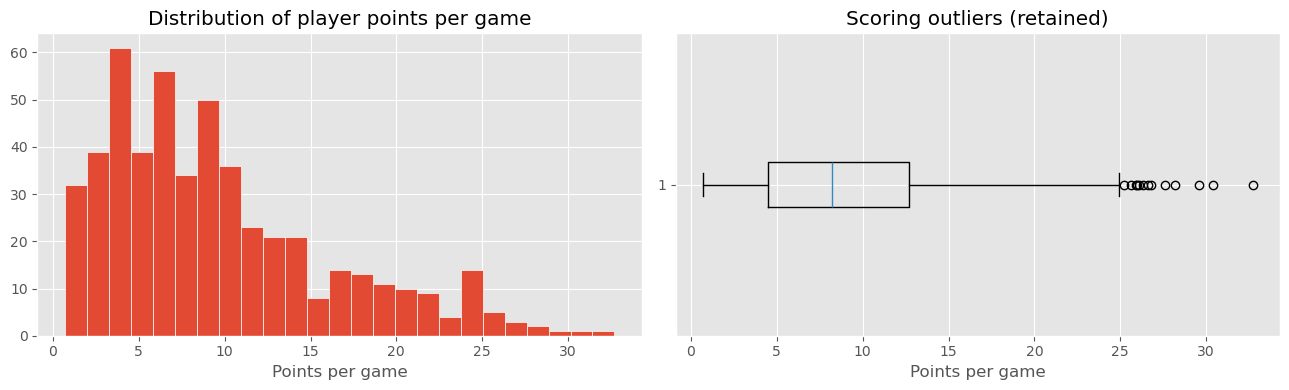

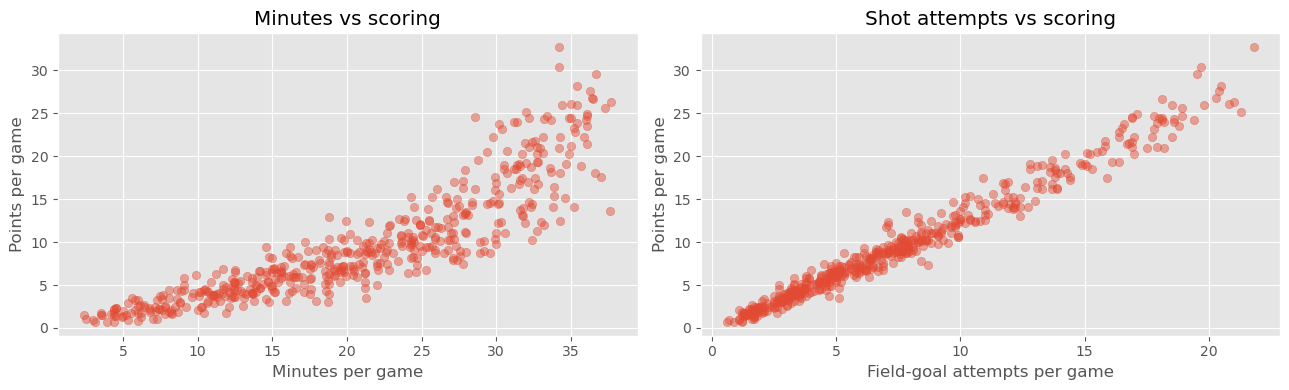

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['PTS'], bins=25, edgecolor='white')
axes[0].set(title='Distribution of player points per game', xlabel='Points per game')
axes[1].boxplot(df['PTS'].dropna(), vert=False)
axes[1].set(title='Scoring outliers (retained)', xlabel='Points per game')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(df['MIN'], df['PTS'], alpha=.45)
axes[0].set(title='Minutes vs scoring', xlabel='Minutes per game', ylabel='Points per game')
if 'FGA' in df:
    axes[1].scatter(df['FGA'], df['PTS'], alpha=.45)
    axes[1].set(title='Shot attempts vs scoring', xlabel='Field-goal attempts per game', ylabel='Points per game')
else:
    axes[1].axis('off')
plt.tight_layout(); plt.show()

Exploratory correlations (not causal effects):


,Pearson r
SHOT_ATTEMPTS,0.991660
FGM,0.991022
FGA,0.986387
WNBA_FANTASY_PTS,0.973299
FP_HIGH_SCORE,0.954791
NBA_FANTASY_PTS,0.950372
FTM,0.909281
PFD,0.903795
FTA,0.896909
MIN,0.883607


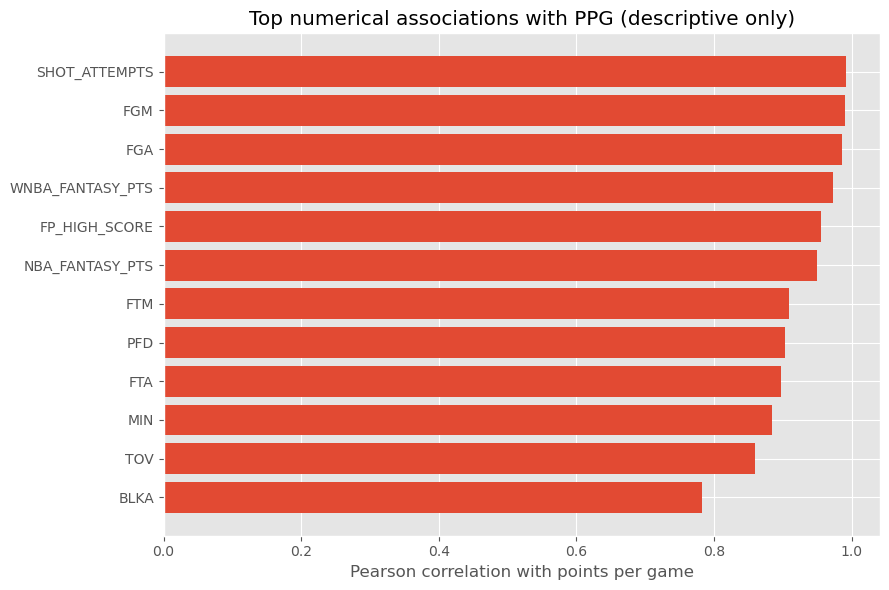

In [6]:
numeric = df.select_dtypes(include='number')
corr = numeric.corr(numeric_only=True)['PTS'].drop('PTS').dropna().sort_values(ascending=False)
# Exclude mechanically derived outcome measures from interpretation.
leakage = {'PTS', 'PTS_RANK', 'PTS_PER36', 'PTS_PER_36', 'POINTS'}
corr_display = corr.drop(labels=[c for c in corr.index if c in leakage], errors='ignore')
print('Exploratory correlations (not causal effects):')
display(corr_display.head(15).to_frame('Pearson r'))
plt.figure(figsize=(9, 6))
plt.barh(corr_display.head(12).index[::-1], corr_display.head(12).values[::-1])
plt.title('Top numerical associations with PPG (descriptive only)')
plt.xlabel('Pearson correlation with points per game'); plt.tight_layout(); plt.show()

## 6. Preliminary model comparison
An 80/20 split provides a first comparison between a mean-only predictor and linear regression. This notebook is exploratory; Performs five-fold cross-validation, model tuning, and final evaluation in the 2nd part. **MAE** represents the average absolute error in points per game.

In [7]:
candidate_features = [
    'MIN', 'GP', 'FGA', 'FG_PCT', 'FG3A', 'FG3_PCT', 'FTA', 'FT_PCT',
    'AST', 'REB', 'STL', 'BLK', 'TOV', 'OREB', 'DREB', 'PF'
]
features = [c for c in candidate_features if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(features) < 3:
    raise ValueError(f'Not enough numeric predictor columns. Found: {features}')
X = df[features].copy()
y = df['PTS'].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
models = {
    'Mean-only baseline': DummyRegressor(strategy='mean'),
    'Linear regression': LinearRegression()
}
rows = []
trained = {}
for name, estimator in models.items():
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if name == 'Linear regression':
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', estimator))
    pipe = Pipeline(steps)
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    })
    trained[name] = pipe
results = pd.DataFrame(rows).sort_values('MAE')
display(results.round(3))
print('Predictor columns:', features)

,Model,MAE,RMSE,R2
1,Linear regression,0.377,0.531,0.993
0,Mean-only baseline,5.145,6.543,-0.009


Predictor columns: ['MIN', 'GP', 'FGA', 'FG_PCT', 'FG3A', 'FG3_PCT', 'FTA', 'FT_PCT', 'AST', 'REB', 'STL', 'BLK', 'TOV', 'OREB', 'DREB', 'PF']


## 7. Model interpretation and residual diagnostics
Permutation importance is calculated on the held-out test set. It reflects predictive reliance, not causal effects. Strongly correlated predictors can share importance.

,Feature,MAE increase when shuffled,Std
2,FGA,5.150,0.197
9,REB,1.502,0.075
14,DREB,1.298,0.052
6,FTA,1.005,0.074
3,FG_PCT,0.417,0.031
13,OREB,0.298,0.039
4,FG3A,0.205,0.016
12,TOV,0.132,0.023
5,FG3_PCT,0.057,0.014
8,AST,0.032,0.006


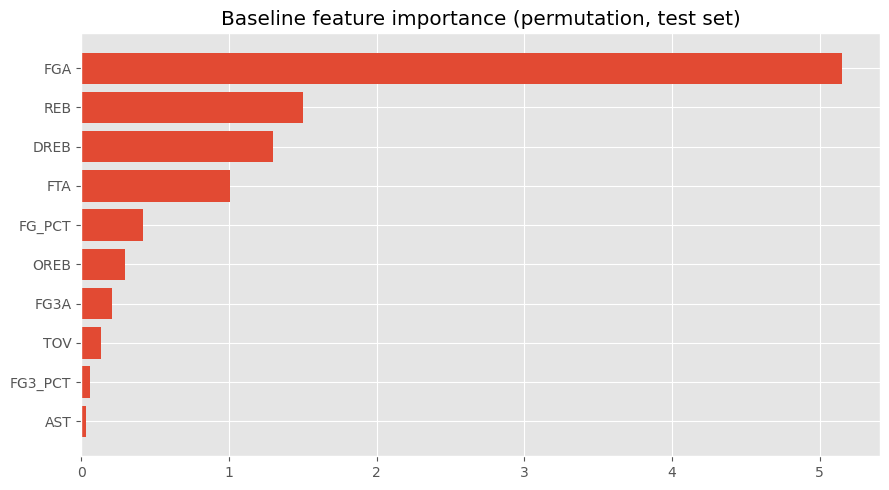

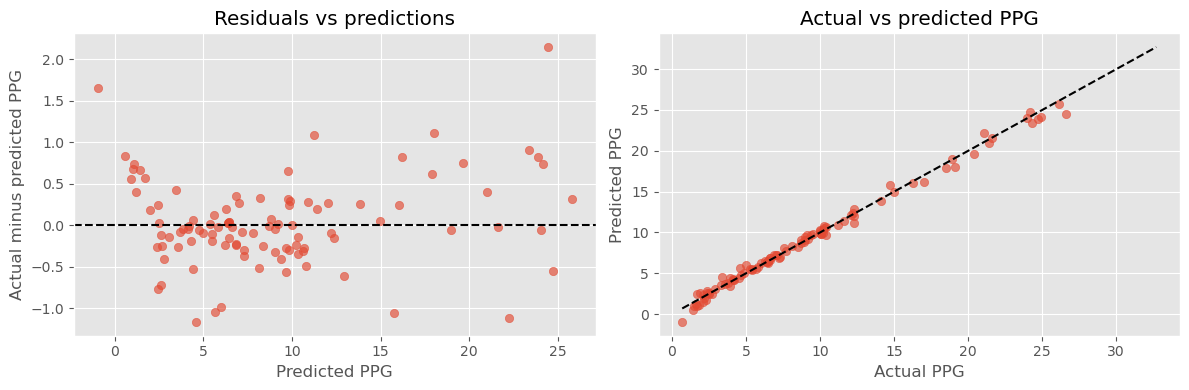

In [8]:
baseline = trained['Linear regression']
importance = permutation_importance(
    baseline, X_test, y_test, scoring='neg_mean_absolute_error',
    n_repeats=10, random_state=RANDOM_STATE
)
importance_df = pd.DataFrame({
    'Feature': features,
    'MAE increase when shuffled': importance.importances_mean,
    'Std': importance.importances_std
}).sort_values('MAE increase when shuffled', ascending=False)
display(importance_df.round(3))
plt.figure(figsize=(9, 5))
plt.barh(importance_df.head(10)['Feature'][::-1], importance_df.head(10)['MAE increase when shuffled'][::-1])
plt.title('Baseline feature importance (permutation, test set)')
plt.tight_layout(); plt.show()
pred = baseline.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred, y_test-pred, alpha=.65)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(title='Residuals vs predictions', xlabel='Predicted PPG', ylabel='Actual minus predicted PPG')
axes[1].scatter(y_test, pred, alpha=.65)
axes[1].plot([y.min(),y.max()], [y.min(),y.max()], '--', color='black')
axes[1].set(title='Actual vs predicted PPG', xlabel='Actual PPG', ylabel='Predicted PPG')
plt.tight_layout(); plt.show()

## 8. Preliminary interpretation
The original executed submission reported a linear-model test MAE of **0.377 PPG**, RMSE **0.531**, and R² **0.993**, versus a mean-only MAE of **5.145** (508 cleaned player records). These are historical notebook outputs, **not independently reproduced here**. They reflect the fact that same-season shot attempts and shooting percentages nearly determine points scored; they should not be described as forecasts. Re-run both notebooks with the exact CSV to verify results.

## 9. Limitations and next steps
- Same-season scoring and attempts are measured concurrently, so results do not establish causation.
- Players with fewer than 10 games are excluded; results do not generalize to all players.
- One season provides limited external validity.
- For real forecasting, can use **prior-season** predictors to predict **next-season** PPG and split by season chronologically.

---
# Part II — Model Comparison, Cross-Validation, Tuning, and Evaluation

Uses a consistent holdout split, five-fold cross-validation, and grid search on training data only. The final holdout is used to report generalization error.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
plt.style.use('ggplot')
DATA_PATH = Path('./data/nba_player_stats.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Missing {DATA_PATH}. See README for dataset instructions.')
raw = pd.read_csv(DATA_PATH)
print('Raw rows:', len(raw))

Raw rows: 569


## 1. Audit and clean the data
Use the same eligibility threshold as the EDA notebook (at least 10 games), remove duplicate records, and avoid treating traded players twice.

In [10]:
required = {'PLAYER_NAME', 'GP', 'MIN', 'PTS'}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f'Missing required fields: {sorted(missing)}')
df = raw.drop_duplicates().copy()
for c in df.columns:
    if c not in ('PLAYER_NAME', 'TEAM_ABBREVIATION', 'NICKNAME'):
        df[c] = pd.to_numeric(df[c], errors='coerce')
for c in ['GP','MIN','PTS']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=['GP','MIN','PTS'])
df = df.loc[df.GP >= 10].copy()
if df.PLAYER_NAME.duplicated().any():
    df['_tot'] = df.get('TEAM_ABBREVIATION',pd.Series('',index=df.index)).eq('TOT').astype(int)
    df = (df.sort_values(['PLAYER_NAME','_tot','GP'],ascending=[True,False,False])
            .drop_duplicates('PLAYER_NAME').drop(columns='_tot'))
print(f'Cleaned players: {len(df)}; missing cells: {int(df.isna().sum().sum())}')
print('PPG descriptive statistics:')
display(df.PTS.describe().round(2).to_frame('PPG'))

Cleaned players: 508; missing cells: 0
PPG descriptive statistics:


,PPG
count,508.00
mean,9.56
std,6.54
min,0.70
25%,4.47
50%,8.20
75%,12.70
max,32.70


## 2. Exploratory visuals
Distribution and playing-time association provide context for model results. These are associations, not causal effects.

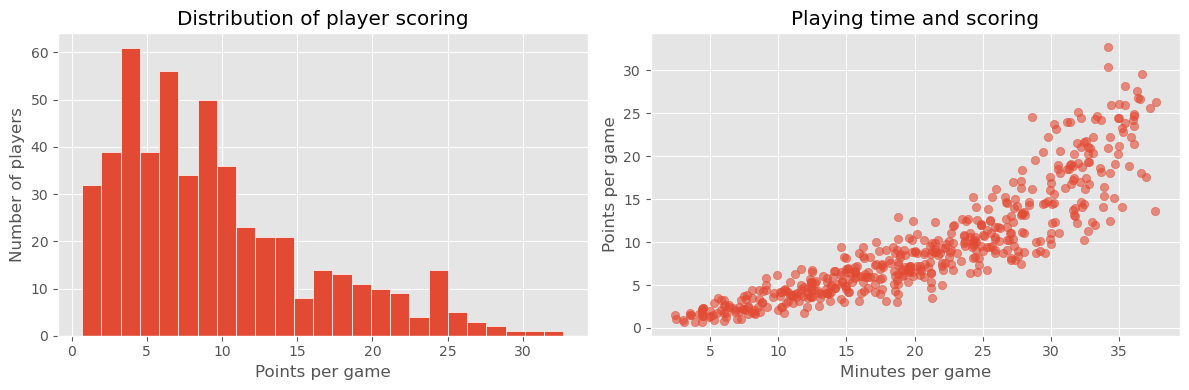

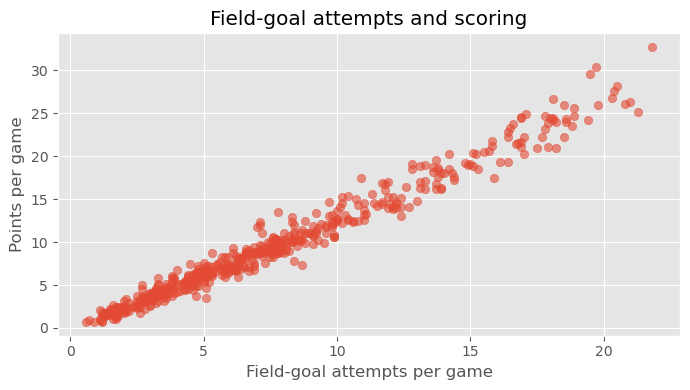

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].hist(df['PTS'], bins=25, edgecolor='white')
ax[0].set(title='Distribution of player scoring', xlabel='Points per game', ylabel='Number of players')
ax[1].scatter(df['MIN'],df['PTS'],alpha=.6)
ax[1].set(title='Playing time and scoring', xlabel='Minutes per game', ylabel='Points per game')
plt.tight_layout(); plt.show()
if 'FGA' in df.columns:
    plt.figure(figsize=(7,4))
    plt.scatter(df['FGA'],df['PTS'],alpha=.6)
    plt.title('Field-goal attempts and scoring');plt.xlabel('Field-goal attempts per game');plt.ylabel('Points per game')
    plt.tight_layout();plt.show()

## 3. Feature selection and holdout split
Only numeric, non-target predictors are used. We exclude scoring ranks, total points and other directly target-derived fields. **The available contemporaneous shot attempts and percentages still mechanically encode scoring**; the interpretation must acknowledge this.

In [12]:
candidate = ['MIN','GP','FGA','FG_PCT','FG3A','FG3_PCT','FTA','FT_PCT',
             'AST','REB','STL','BLK','TOV','OREB','DREB','PF']
features = [c for c in candidate if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(features) < 3:
    raise ValueError('Need at least 3 numeric predictor columns.')
X, y = df[features], df.PTS.astype(float)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=SEED)
print('Training / holdout:',len(X_train),len(X_test));print('Features:',features)

Training / holdout: 406 102
Features: ['MIN', 'GP', 'FGA', 'FG_PCT', 'FG3A', 'FG3_PCT', 'FTA', 'FT_PCT', 'AST', 'REB', 'STL', 'BLK', 'TOV', 'OREB', 'DREB', 'PF']


## 4. Cross-validation and hyperparameter search
Five-fold shuffled cross-validation evaluates candidates only on training rows. Pipelines fit imputation and scaling inside each fold, preventing preprocessing leakage. Grid search selects hyperparameters using negative MAE.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
def make_pipe(estimator, scale=False):
    steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scaler',StandardScaler()))
    return Pipeline(steps+[('model',estimator)])
searches = {
    'Mean baseline': (make_pipe(DummyRegressor()), {}),
    'Linear regression': (make_pipe(LinearRegression(),True), {}),
    'Ridge': (make_pipe(Ridge(),True), {'model__alpha':[0.1,1,10,100]}),
    'Random forest': (make_pipe(RandomForestRegressor(random_state=SEED,n_jobs=1)),
                      {'model__n_estimators':[100,200],'model__max_depth':[5,None],
                       'model__min_samples_leaf':[1,3]}),
    'Gradient boosting': (make_pipe(HistGradientBoostingRegressor(random_state=SEED)),
                          {'model__max_iter':[100,200],'model__learning_rate':[.05,.1],
                           'model__max_leaf_nodes':[15,31]})
}
rows=[]; fitted={}
for name,(pipe,grid) in searches.items():
    if grid:
        search=GridSearchCV(pipe,grid,scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,refit=True)
        search.fit(X_train,y_train)
        fitted[name]=search.best_estimator_
        score=-search.best_score_; params=search.best_params_
    else:
        scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring='neg_mean_absolute_error')
        score=-scores['test_score'].mean();params={}
        fitted[name]=pipe.fit(X_train,y_train)
    rows.append({'Model':name,'CV MAE (PPG)':score,'Best parameters':str(params)})
cv_results=pd.DataFrame(rows).sort_values('CV MAE (PPG)').reset_index(drop=True)
display(cv_results.round(3))

,Model,CV MAE (PPG),Best parameters
0,Ridge,0.425,{'model__alpha': 1}
1,Linear regression,0.429,{}
2,Gradient boosting,0.495,"{'model__learning_rate': 0.05, 'model__max_ite..."
3,Random forest,0.596,"{'model__max_depth': None, 'model__min_samples..."
4,Mean baseline,5.193,{}


## 5. Final test evaluation
The winner is selected by training CV MAE, then assessed once on untouched holdout data. Other holdout scores are presented for descriptive comparison, **not** for selecting a different winner.

,Model,Test MAE (PPG),Test RMSE (PPG),Test R²
4,Gradient boosting,0.333,0.471,0.995
1,Linear regression,0.377,0.531,0.993
2,Ridge,0.379,0.533,0.993
3,Random forest,0.491,0.723,0.988
0,Mean baseline,5.145,6.543,-0.009


Selected by CV: Ridge


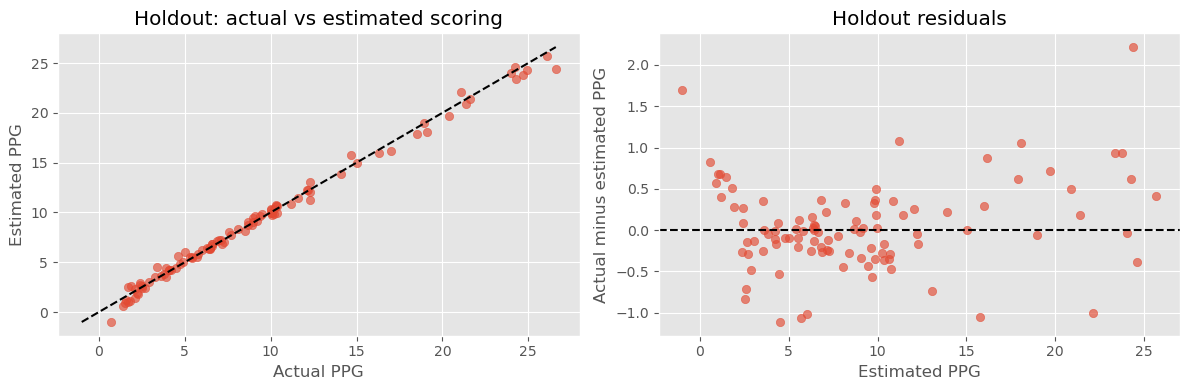

In [14]:
winner=cv_results.iloc[0]['Model']
test_rows=[]
for name,model in fitted.items():
    p=model.predict(X_test)
    test_rows.append({'Model':name,'Test MAE (PPG)':mean_absolute_error(y_test,p),
                      'Test RMSE (PPG)':np.sqrt(mean_squared_error(y_test,p)),
                      'Test R²':r2_score(y_test,p)})
test_results=pd.DataFrame(test_rows).sort_values('Test MAE (PPG)')
display(test_results.round(3))
print('Selected by CV:',winner)
pred=fitted[winner].predict(X_test)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].scatter(y_test,pred,alpha=.65);lo=min(y_test.min(),pred.min());hi=max(y_test.max(),pred.max())
ax[0].plot([lo,hi],[lo,hi],'k--');ax[0].set(title='Holdout: actual vs estimated scoring',xlabel='Actual PPG',ylabel='Estimated PPG')
ax[1].scatter(pred,y_test-pred,alpha=.65);ax[1].axhline(0,color='black',ls='--')
ax[1].set(title='Holdout residuals',xlabel='Estimated PPG',ylabel='Actual minus estimated PPG')
plt.tight_layout();plt.show()

## 6. Explain important factors
Permutation importance estimates how much held-out MAE worsens when a feature is shuffled. Highly correlated features share information, so rankings can be unstable and **do not establish causation**.

,Feature,MAE increase (PPG)
2,FGA,4.934
6,FTA,1.055
3,FG_PCT,0.422
4,FG3A,0.254
14,DREB,0.121
12,TOV,0.094
5,FG3_PCT,0.056
8,AST,0.031
15,PF,0.019
7,FT_PCT,0.009


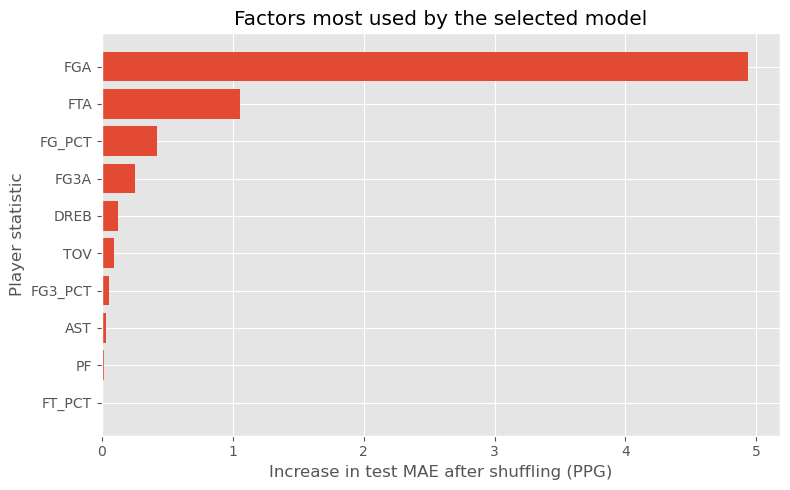

In [15]:
imp=permutation_importance(fitted[winner],X_test,y_test,scoring='neg_mean_absolute_error',
                           n_repeats=10,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'Feature':features,'MAE increase (PPG)':imp.importances_mean})
importance=importance.sort_values('MAE increase (PPG)',ascending=False)
display(importance.head(10).round(3))
plt.figure(figsize=(8,5));plt.barh(importance.head(10)['Feature'][::-1],importance.head(10)['MAE increase (PPG)'][::-1])
plt.title('Factors most used by the selected model');plt.xlabel('Increase in test MAE after shuffling (PPG)')
plt.ylabel('Player statistic');plt.tight_layout();plt.show()

## 7. Sensitivity analysis: reduce direct scoring reconstruction
To evaluate whether relationships persist without shot-volume and shooting-percentage components, repeat CV with non-shooting features only. This is still same-season explanatory analysis, not future prediction.

In [16]:
context_features=[c for c in ['MIN','GP','AST','REB','STL','BLK','TOV','OREB','DREB','PF'] if c in X.columns]
if len(context_features)>=3:
    context_model=make_pipe(Ridge(alpha=10),True)
    scores=cross_validate(context_model,X_train[context_features],y_train,cv=cv,
                          scoring='neg_mean_absolute_error')
    print(f'Context-only Ridge training CV MAE: {-scores["test_score"].mean():.3f} PPG')
else:
    print('Insufficient non-shooting features for sensitivity analysis.')

Context-only Ridge training CV MAE: 1.760 PPG


## 8. Conclusions and next steps
- Compare the selected model's **test MAE** with the mean-only baseline; lower MAE means a smaller typical error in PPG.
- Interpret high same-season accuracy carefully: field-goal attempts, free-throw attempts and shooting percentages are directly involved in calculating points.
- Use results to **describe** scoring profiles, not to predict future games or infer that increasing a single statistic causes higher scoring.
- Next steps: add prior-season predictors, evaluate on a later held-out season, analyze performance by minutes played and position, and report uncertainty.

---
# Final Nontechnical Summary and Recommendations

**What this project answers:** NBA scoring is closely linked to playing time and shooting opportunities. Models can estimate a player’s points per game from statistics collected during the same season.

**How to interpret results:** Mean absolute error (MAE) is the average difference between estimated and actual points per game; smaller is better. R² indicates how much of the variation in observed scoring the model explains. The cross-validation winner is chosen without looking at holdout performance.

**Practical takeaways:** Use shot volume and playing time as descriptive indicators of scoring opportunity. Use the reduced-feature sensitivity model to see how accuracy changes without direct shot-attempt measures. Do not interpret correlations or permutation importance as proof that changing one statistic will cause points to increase.

**Limitations:** Data is observational, excludes players with fewer than ten games, and contains within-season measurements. Shooting statistics are mechanically related to scoring, making this task easier than forecasting future points.

**Next steps:** (1) Build a season-to-season forecasting dataset with features strictly from prior seasons; (2) evaluate across seasons rather than only a random player split; (3) report performance separately for guards, forwards, centers, and low-minute players; (4) add uncertainty intervals and investigate role/team effects.

**Reproducibility:** Run all cells from top to bottom. Dataset is embedded in the notebook. Libraries used include pandas, NumPy, Matplotlib, seaborn, and scikit-learn.